In [1]:
%load_ext autoreload
%autoreload 2

import os

os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"
os.environ["PYOPENGL_PLATFORM"] = "egl"
os.environ["MUJOCO_GL"] = "egl"

import functools
import gc

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from brax.training.acme import running_statistics, specs
from brax.training.agents.ppo import networks as ppo_networks

from vnl_playground.tasks.rodent import consts as rodent_consts
from vnl_playground.tasks.rodent import bowl_escape

from scamper.agent.task_transfer.bowl_escape.checkpoint_utils import (
    load_prior_checkpoint,
    load_task_transfer_metadata,
    load_task_transfer_brax_params,
    make_decoder_inference_fn,
    make_prior_inference_fn,
)
from scamper.agent.task_transfer.bowl_escape.wrappers import (
    DecoderHighLevelWrapper,
    FlatObsWrapper,
    PriorDecoderHighLevelWrapper,
)
from scamper.agent.task_transfer.bowl_escape.scratch_networks import (
    make_scratch_ppo_networks,
)

In [2]:
CKPT_BASE = "/home/mila/a/aidan.sirbu/SCAMPER/scratch/bowl_escape_checkpoints"

CHECKPOINT_PATHS = [
    # Add your bowl escape checkpoint paths here
    # f"{CKPT_BASE}/YYMMDD_HHMMSS_ffffff",
    f"{CKPT_BASE}/260220_120221_406301",
    f"{CKPT_BASE}/260220_103147_618597",
]

EPISODE_LENGTH = 2000  # Rollout steps (matches bowl escape config)
SEED = 0  # Single rollout seed per model

In [3]:
def load_model(checkpoint_path, checkpoint_step=None):
    """Load a trained bowl_escape model and return everything needed for rollouts.

    Returns:
        (jit_reset, jit_step, jit_inference_fn, brax_params, config)
    """
    # Load metadata
    ckpt_info = load_task_transfer_metadata(checkpoint_path, step=checkpoint_step)
    config = ckpt_info["config"]
    ckpt_step = ckpt_info["step"]
    mode = config["mode"]
    ckpt_cfg = config["checkpoint_config"]

    print(f"Loading checkpoint: {checkpoint_path}")
    print(f"  Mode: {mode}, Step: {ckpt_step}")

    # Load frozen networks from prior checkpoint
    prior_checkpoint_path = config["checkpoint"]["path"]
    prior_checkpoint_step = config["checkpoint"]["step"]

    (
        encoder_params,
        prior_params,
        decoder_params,
        normalizer_params,
        _,
    ) = load_prior_checkpoint(prior_checkpoint_path, prior_checkpoint_step)

    latent_size = ckpt_cfg["network_config"]["intention_size"]
    proprio_size = ckpt_cfg["network_config"]["obs_sizes"]["proprioception"]

    # Create environment
    env_cfg = bowl_escape.default_config()

    xml_variant = config["env"].get("xml_variant", "full-collisions")
    if xml_variant == "limited-collisions":
        env_cfg.walker_xml_path = rodent_consts.RODENT_XML_PATH
    elif xml_variant == "full-collisions":
        env_cfg.walker_xml_path = rodent_consts.RODENT_FULL_COLLISION_XML
    elif xml_variant == "no-tail-collisions":
        env_cfg.walker_xml_path = rodent_consts.RODENT_NO_TAIL_COLLISION_XML
    else:
        raise ValueError(f"Unknown xml_variant: {xml_variant}")

    env_cfg.mujoco_impl = config["env"].get("mujoco_impl", "jax")
    env_cfg.ctrl_dt = ckpt_cfg["env_config"]["ctrl_dt"]
    env_cfg.torque_actuators = True

    # Set actuator type for scratch mode
    if mode == "scratch":
        env_cfg.torque_actuators = config["scratch"].get("torque_actuators", True)

    # Create decoder inference function and wrap environment
    decoder_fn = make_decoder_inference_fn(decoder_params, normalizer_params, ckpt_cfg)

    import mujoco
    from mujoco import mjx

    base_env = bowl_escape.BowlEscape(config=env_cfg)

    # Increase CCD iterations to suppress warnings
    base_env._mj_model.opt.ccd_iterations = 50

    # Modify heightfield friction if specified
    hfield_friction = config["env"].get("hfield_friction")
    if hfield_friction is not None:
        for i in range(base_env._mj_model.ngeom):
            if base_env._mj_model.geom_type[i] == mujoco.mjtGeom.mjGEOM_HFIELD:
                base_env._mj_model.geom_friction[i, 0] = hfield_friction
                break

    # Re-put model to MJX after modifications
    base_env._mjx_model = mjx.put_model(
        base_env._mj_model, impl=env_cfg.mujoco_impl
    )

    if mode == "decoder_only":
        env = DecoderHighLevelWrapper(base_env, decoder_fn, latent_size, proprio_size)
    elif mode == "scratch":
        env = FlatObsWrapper(base_env)
    elif mode == "prior_decoder":
        prior_fn = make_prior_inference_fn(prior_params, normalizer_params, ckpt_cfg)
        env = PriorDecoderHighLevelWrapper(
            base_env,
            prior_fn,
            decoder_fn,
            latent_size,
            proprio_size,
            deterministic_prior=config["prior_decoder"]["deterministic_prior"],
            noise_logvar=config["prior_decoder"]["noise_logvar"],
        )
    else:
        raise ValueError(f"Unknown mode: {mode}")

    # JIT-compile reset and step
    jit_reset = jax.jit(env.reset)
    jit_step = jax.jit(env.step)

    # Build network and load parameters
    rng = jax.random.PRNGKey(0)
    start_state = jit_reset(rng)
    obs_size = start_state.obs.shape[-1]
    normalize = running_statistics.normalize
    policy_action_size = env.action_size

    if mode == "scratch":
        def network_factory(*args, **kwargs):
            return make_scratch_ppo_networks(
                obs_size=obs_size,
                action_size=policy_action_size,
                policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
                value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
            )

        dummy_net = network_factory()
    else:
        network_factory = functools.partial(
            ppo_networks.make_ppo_networks,
            policy_hidden_layer_sizes=tuple(config["network"]["policy_layers"]),
            value_hidden_layer_sizes=tuple(config["network"]["value_layers"]),
        )
        dummy_net = network_factory(
            obs_size, policy_action_size, preprocess_observations_fn=normalize
        )

    key_p, key_v = jax.random.split(jax.random.PRNGKey(0))
    dummy_normalizer = running_statistics.init_state(
        specs.Array(start_state.obs.shape[-1:], jnp.dtype("float32"))
    )
    dummy_policy = dummy_net.policy_network.init(key_p)
    dummy_value = dummy_net.value_network.init(key_v)
    abstract_brax_params = (dummy_normalizer, dummy_policy, dummy_value)

    brax_params = load_task_transfer_brax_params(
        checkpoint_path, abstract_brax_params, step=ckpt_step
    )

    # Create deterministic inference function
    if mode == "scratch":
        ppo_network = network_factory()
    else:
        ppo_network = network_factory(
            obs_size, policy_action_size, preprocess_observations_fn=normalize
        )

    policy_network = ppo_network.policy_network
    parametric_action_distribution = ppo_network.parametric_action_distribution

    def inference_fn(params, observations, key_sample):
        del key_sample  # Deterministic
        param_subset = (params[0], params[1])
        logits = policy_network.apply(*param_subset, observations)
        action = parametric_action_distribution.mode(logits)
        return action, {}

    jit_inference_fn = jax.jit(inference_fn)

    print(f"  Model loaded successfully.")
    return jit_reset, jit_step, jit_inference_fn, brax_params, config

In [4]:
def run_rollout(jit_reset, jit_step, jit_inference_fn, brax_params, seed, episode_length):
    """Run a single rollout and return per-step distance from bowl center.

    Computes distance as ||qpos[:2]|| (Euclidean distance of root body from origin
    in the x-y ground plane).

    Returns:
        np.ndarray of shape (episode_length,) with distance at each timestep.
    """
    rng = jax.random.PRNGKey(seed)
    reset_rng, act_rng = jax.random.split(rng)

    state = jit_reset(reset_rng)
    distances = []

    for _ in range(episode_length):
        _, act_rng = jax.random.split(act_rng)
        action, _ = jit_inference_fn(brax_params, state.obs, act_rng)
        state = jit_step(state, action)
        # Root body x,y position
        x, y = float(state.data.qpos[0]), float(state.data.qpos[1])
        distances.append(np.sqrt(x**2 + y**2))

    return np.array(distances)

In [5]:
# Run one rollout per model, clearing memory after each
from collections import defaultdict

raw_results = []  # List of (mode, distances_array)

for i, ckpt_path in enumerate(CHECKPOINT_PATHS):
    print(f"[{i + 1}/{len(CHECKPOINT_PATHS)}]")
    jit_reset, jit_step, jit_inference_fn, brax_params, config = load_model(ckpt_path)
    mode = config["mode"]

    distances = run_rollout(
        jit_reset, jit_step, jit_inference_fn, brax_params, SEED, EPISODE_LENGTH
    )
    raw_results.append((mode, distances))
    print(f"  Mode: {mode}, Final distance: {distances[-1]:.3f} m")

    # Free model objects and clear caches to avoid OOM
    del jit_reset, jit_step, jit_inference_fn, brax_params, config
    jax.clear_caches()
    gc.collect()
    print()

# Group by mode
grouped = defaultdict(list)
for mode, distances in raw_results:
    grouped[mode].append(distances)

print("Summary:")
for mode in sorted(grouped):
    n = len(grouped[mode])
    final_dists = [d[-1] for d in grouped[mode]]
    print(f"  {mode}: n={n}, final distance = {np.mean(final_dists):.3f} +/- {np.std(final_dists):.3f} m")

[1/2]
Loading checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/bowl_escape_checkpoints/260220_120221_406301
  Mode: prior_decoder, Step: 57
Initial position: 0.0, 0.0, 0.009999999776482582
Warp 1.11.0 initialized:
   CUDA Toolkit 12.9, Driver 13.0
   Devices:
     "cpu"      : "x86_64"
     "cuda:0"   : "Quadro RTX 8000" (44 GiB, sm_75, mempool enabled)
   Kernel cache:
     /home/mila/a/aidan.sirbu/.cache/warp/1.11.0
Warp DeprecationWarning: The symbol `warp.types.warp_type_to_np_dtype` will soon be removed from the public API. It can still be accessed from `warp._src.types.warp_type_to_np_dtype` but might be changed or removed without notice.
Module mujoco.mjx.third_party.mujoco_warp._src.smooth e142b0f load on device 'cuda:0' took 16.86 ms  (cached)
Module mujoco.mjx.third_party.mujoco_warp._src.collision_driver de6dc98 load on device 'cuda:0' took 5.21 ms  (cached)
Module _nxn_broadphase__locals__kernel_8c837afb 8c837af load on device 'cuda:0' took 4.70 ms  (cached)
Module ccd_

E0305 11:29:41.300341  454632 slow_operation_alarm.cc:73] Constant folding an instruction is taking > 1s:

  %reduce_sum.99 = s32[] reduce(%constant.120, %constant.198), dimensions={0}, to_apply=%region_2.10, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=106}

This isn't necessarily a bug; constant-folding is inherently a trade-off between compilation time and speed at runtime. XLA has some guards that attempt to keep constant folding from taking too long, but fundamentally you'll always be able to come up with an input program that takes a long time.

If you'd like to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
E0305 11:29:52.921071  447843 slow_operation_alarm.cc:140] The operation took 12.620871314s
Constant folding an instruction is taking > 1s:

  %reduce_sum.99 = s32[] reduce(%constant.120, %constant.198), dimensions={0}, to_apply=%region_2.10, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=106}

This isn't necessarily

  Model loaded successfully.
Module mujoco.mjx.warp.ffi edde159 load on device 'cuda:0' took 5.36 ms  (cached)
  Mode: prior_decoder, Final distance: 1.993 m

[2/2]
Loading checkpoint: /home/mila/a/aidan.sirbu/SCAMPER/scratch/bowl_escape_checkpoints/260220_103147_618597
  Mode: decoder_only, Step: 70
Initial position: 0.0, 0.0, 0.009999999776482582


E0305 11:31:37.794888  454632 slow_operation_alarm.cc:73] Constant folding an instruction is taking > 2s:

  %reduce_sum.57 = s32[] reduce(%constant.103, %constant.178), dimensions={0}, to_apply=%region_2.10, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=106}

This isn't necessarily a bug; constant-folding is inherently a trade-off between compilation time and speed at runtime. XLA has some guards that attempt to keep constant folding from taking too long, but fundamentally you'll always be able to come up with an input program that takes a long time.

If you'd like to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
E0305 11:31:48.362622  447843 slow_operation_alarm.cc:140] The operation took 12.567889338s
Constant folding an instruction is taking > 2s:

  %reduce_sum.57 = s32[] reduce(%constant.103, %constant.178), dimensions={0}, to_apply=%region_2.10, metadata={op_name="jit(reset)/reduce_sum" stack_frame_id=106}

This isn't necessarily

  Model loaded successfully.
  Mode: decoder_only, Final distance: 3.482 m

Summary:
  decoder_only: n=1, final distance = 3.482 +/- 0.000 m
  prior_decoder: n=1, final distance = 1.993 +/- 0.000 m


In [6]:
# Save rollout results for reuse without re-running rollouts
import pandas as pd
from pathlib import Path

save_dir = Path("/home/mila/a/aidan.sirbu/SCAMPER/data/bowl_escape_analysis")
save_dir.mkdir(parents=True, exist_ok=True)

# Save as a long-format CSV: mode, timestep, distance
rows = []
for rollout_idx, (mode, distances) in enumerate(raw_results):
    for t, d in enumerate(distances):
        rows.append({"rollout_idx": rollout_idx, "mode": mode, "timestep": t, "distance": d})

df_results = pd.DataFrame(rows)
csv_path = save_dir / "bowl_escape_distance_rollouts.csv"
df_results.to_csv(csv_path, index=False)
print(f"Saved {len(df_results)} rows ({len(raw_results)} rollouts) to {csv_path}")
df_results.head()

Saved 4000 rows (2 rollouts) to /home/mila/a/aidan.sirbu/SCAMPER/data/bowl_escape_analysis/bowl_escape_distance_rollouts.csv


,rollout_idx,mode,timestep,distance
0,0,prior_decoder,0,0.006052
1,0,prior_decoder,1,0.017476
2,0,prior_decoder,2,0.015305
3,0,prior_decoder,3,0.017163
4,0,prior_decoder,4,0.022373


In [ ]:
# Load rollout results from CSV (skip cells 0-5 if data already saved)
import pandas as pd
import numpy as np
from pathlib import Path
from collections import defaultdict

csv_path = Path("/home/mila/a/aidan.sirbu/SCAMPER/data/bowl_escape_analysis/bowl_escape_distance_rollouts.csv")
df_loaded = pd.read_csv(csv_path)

# Reconstruct grouped dict: mode -> list of distance arrays
grouped = defaultdict(list)
for rollout_idx in df_loaded["rollout_idx"].unique():
    rollout_df = df_loaded[df_loaded["rollout_idx"] == rollout_idx].sort_values("timestep")
    mode = rollout_df["mode"].iloc[0]
    grouped[mode].append(rollout_df["distance"].values)

print(f"Loaded {len(df_loaded['rollout_idx'].unique())} rollouts from {csv_path}")
print(f"Modes: {sorted(grouped.keys())}")
for mode in sorted(grouped):
    print(f"  {mode}: n={len(grouped[mode])}")

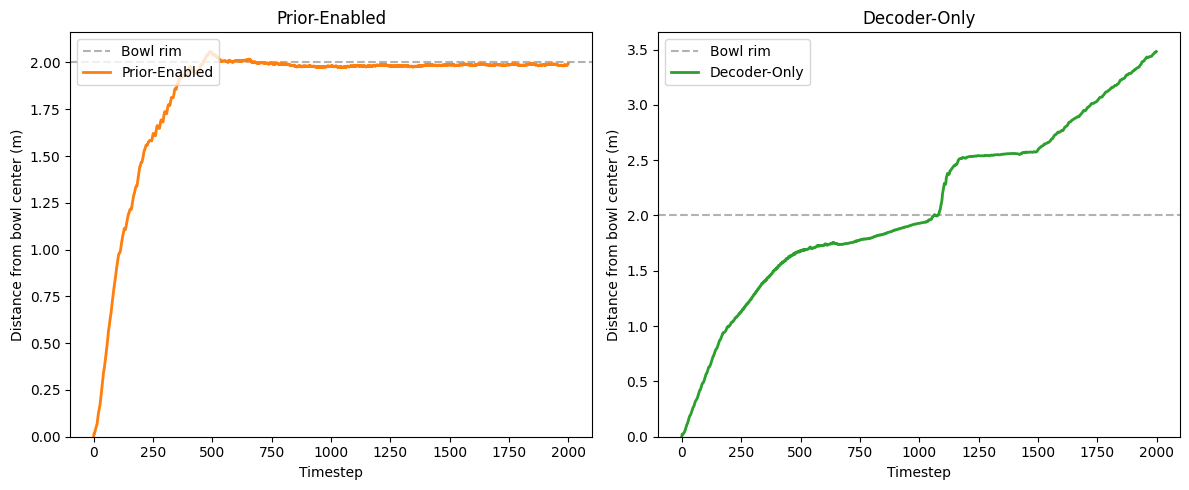

In [7]:
# Plot distance from bowl center over time, one subplot per training mode
import matplotlib.pyplot as plt

MODE_LABELS = {
    "scratch": "Scratch",
    "prior_decoder": "Prior-Enabled",
    "decoder_only": "Decoder-Only",
}
MODE_COLORS = {
    "scratch": "tab:blue",
    "prior_decoder": "tab:orange",
    "decoder_only": "tab:green",
}
MODE_ORDER = ["scratch", "prior_decoder", "decoder_only"]

BOWL_HSIZE = 2.0  # Bowl rim radius (from default config)

# Only plot modes that have data
modes_with_data = [m for m in MODE_ORDER if m in grouped]

fig, axes = plt.subplots(1, len(modes_with_data), figsize=(6 * len(modes_with_data), 5))
if len(modes_with_data) == 1:
    axes = [axes]

for ax, mode in zip(axes, modes_with_data):
    all_dists = np.array(grouped[mode])  # (n_rollouts, episode_length)
    timesteps = np.arange(all_dists.shape[1])
    mean_dist = np.mean(all_dists, axis=0)
    std_dist = np.std(all_dists, axis=0)
    color = MODE_COLORS[mode]

    # Bowl rim reference line
    ax.axhline(BOWL_HSIZE, color="gray", linestyle="--", alpha=0.6, label="Bowl rim")

    # Individual rollouts (thin lines)
    for dists in all_dists:
        ax.plot(timesteps, dists, color=color, alpha=0.15, linewidth=0.5)

    # Mean +/- std
    ax.plot(timesteps, mean_dist, color=color, linewidth=2, label=MODE_LABELS[mode])
    ax.fill_between(timesteps, mean_dist - std_dist, mean_dist + std_dist, alpha=0.2, color=color)

    ax.set_xlabel("Timestep")
    ax.set_ylabel("Distance from bowl center (m)")
    ax.set_title(MODE_LABELS[mode])
    ax.legend(loc="upper left")
    ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

Saved to /home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/rl_performance/bowl_escape_distance.[pdf|svg|png]


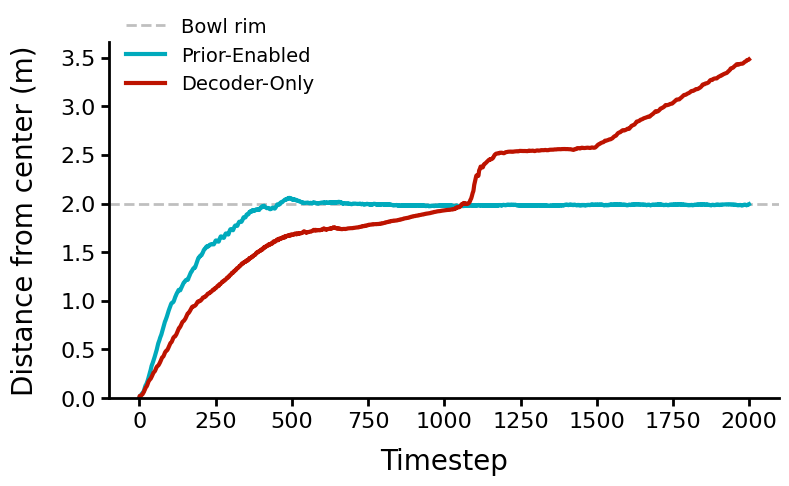

In [8]:
# Combined plot: all modes on one axis
import seaborn as sns

save_dir = Path("/home/mila/a/aidan.sirbu/SCAMPER/notebooks/plots/rl_performance")
save_dir.mkdir(parents=True, exist_ok=True)
save_name = "bowl_escape_distance"

# Build long-format DataFrame for seaborn
plot_rows = []
for mode in modes_with_data:
    for dists in grouped[mode]:
        for t, d in enumerate(dists):
            plot_rows.append({
                "Timestep": t,
                "Distance from center (m)": d,
                "Training Mode": MODE_LABELS[mode],
            })

df_plot = pd.DataFrame(plot_rows)

palette = {
    "Prior-Enabled": tuple(c / 255 for c in (0, 170, 188)),
    "Decoder-Only": tuple(c / 255 for c in (189, 19, 0)),
    "Scratch": tuple(c / 255 for c in (150, 150, 150)),
}
hue_order = [MODE_LABELS[m] for m in modes_with_data]

fig, ax = plt.subplots(figsize=(8, 5))

# Bowl rim reference
ax.axhline(BOWL_HSIZE, color="gray", linestyle="--", alpha=0.5, linewidth=2, label="Bowl rim")

sns.lineplot(
    data=df_plot,
    x="Timestep",
    y="Distance from center (m)",
    hue="Training Mode",
    hue_order=hue_order,
    palette=palette,
    errorbar="sd",
    linewidth=3,
    ax=ax,
)

ax.set_xlabel("Timestep", fontsize=20, labelpad=12)
ax.set_ylabel("Distance from center (m)", fontsize=20, labelpad=16)
ax.tick_params(labelsize=16, width=2, length=6)
ax.set_ylim(bottom=0)

sns.despine(ax=ax)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_linewidth(2)

ax.legend(fontsize=14, frameon=False, loc="upper left", bbox_to_anchor=(0.0, 1.12))

plt.tight_layout()

fig.savefig(save_dir / f"{save_name}.pdf", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.svg", bbox_inches="tight")
fig.savefig(save_dir / f"{save_name}.png", bbox_inches="tight")
print(f"Saved to {save_dir / save_name}.[pdf|svg|png]")

plt.show()